In [1]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt 

In [4]:
image = cv2.imread('../Data/Dog.jpg')

In [5]:
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [6]:
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

In [7]:
#sobel X kernel
sobel_x = np.array(
  [[-1,0,1],
   [-2,0,2],
    [-1,0,1]],
  dtype=float
)

#sobel Y kernel
sobel_y = np.array(
  [[-1,-2,-1],
   [0,0,0],
    [1,2,1]],
  dtype=float
)


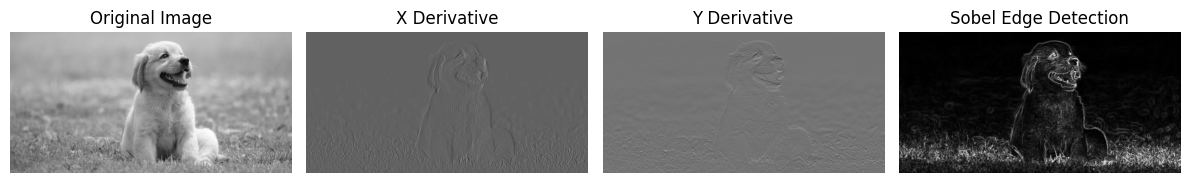

In [8]:
# Apply Kernel Mannually
def apply_kernel(image, kernel):
  height, width = image.shape
  
  padded = np.pad(
    image,1,mode="edge"
  )
  
  output = np.zeros((height, width), dtype=float)
  
  #Apply Convolution
  for i in range(height):
    for j in range(width):
      windowc=padded[i:i+3, j:j+3]
      output[i,j] = np.sum(windowc*kernel)
  
  return output

#calculate X and Y Derivatives 
lx = apply_kernel(gray, sobel_x)
ly = apply_kernel(gray, sobel_y)

#calculate Gradient Magnitude
gradient_magnitude = np.sqrt(lx**2 + ly**2)

#convert to displayable format
magnitude_display = np.clip(gradient_magnitude, 0, 255).astype(np.uint8)
#Display Results
plt.figure(figsize=(12, 8)) 


plt.subplot(1,4,1)
plt.imshow(gray, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,4,2)
plt.imshow(lx, cmap='gray')
plt.title('X Derivative')
plt.axis('off')

plt.subplot(1,4,3)
plt.imshow(ly, cmap='gray')
plt.title('Y Derivative')
plt.axis('off')

plt.subplot(1,4,4)
plt.imshow(magnitude_display, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('off')

plt.tight_layout()
plt.show()
